# 01. PaySim: EDA, проверка утечки и бейзлайн
**Задача №8 (Р1).** Пункт кейса 4.

Что делаем:
1. Оставляем только `TRANSFER` и `CASH_OUT` — мошенничество в PaySim встречается только в них.
2. Проверяем утечку через колонки балансов и **не строим модель на них**.
3. Строим признаки, доступные банку в момент операции: сумма относительно истории, новый получатель, связка «перевод → вывод».
4. LightGBM, сплит по времени (`step`), метрики по формулам кейса.

**Данные:** Kaggle → Add Input → `ealaxi/paysim1`.

### Общие функции
Сплит по времени, метрики по формулам кейса, цена ошибки, симуляция реакции. Ячейка записывает модуль `antifraud_utils.py` рядом с ноутбуком.

In [1]:
%%writefile antifraud_utils.py
"""
Общие функции для ноутбуков команды (Хакатон ВТБ, задача №6).

Метрики считаются строго по формулам кейса (с. 10):
  точность выявления          = TP / (TP + FP)
  доля ложных сигналов        = FP / (TP + FP)
  FPR (ложные среди законных) = FP / (FP + TN)
  полнота обнаружения         = TP / (TP + FN)
Дополнительно: полнота по сумме (какая доля похищаемых денег остановлена).

Этот же код вставлен первой ячейкой в каждый ноутбук, чтобы ноутбуки
запускались на Kaggle без дополнительных файлов.
"""
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score


# ---------------------------------------------------------------- сплит
def time_split(df, time_col, fracs=(0.6, 0.2, 0.2)):
    """Сплит по времени: train — самые ранние операции, test — самые поздние.
    Случайный сплит запрещён: он подмешивает «будущее» в обучение и завышает метрики."""
    t = df[time_col]
    q1 = t.quantile(fracs[0])
    q2 = t.quantile(fracs[0] + fracs[1])
    train = df[t <= q1]
    valid = df[(t > q1) & (t <= q2)]
    test = df[t > q2]
    return train, valid, test


# ---------------------------------------------------------------- история клиента без утечки
def past_stats(df, group_cols, time_col, value_col, lag=0, window=None):
    """Статистики по ПРОШЛЫМ операциям группы (клиент, клиент+категория, получатель...).

    Для строки с временем t учитываются операции той же группы со временем < t − lag
    (и, если задано window, ≥ t − lag − window). Текущая операция и будущее не учитываются.
    lag=0      — онлайн-признак (поток операций доступен сразу)
    lag=86400  — «ночной профиль»: данные приходят с задержкой до суток (условие кейса)
    Возвращает DataFrame (cnt, sum, mean, std) в порядке индекса df. Векторизовано.
    """
    g = df.groupby(group_cols, sort=False).ngroup().to_numpy().astype(np.int64)
    t = df[time_col].to_numpy().astype(np.int64)
    v = df[value_col].to_numpy().astype(float)
    t = t - t.min()
    big = np.int64(t.max() + lag + (window or 0) + 2)
    key = g * big + t
    order = np.argsort(key, kind="mergesort")
    ks, vs = key[order], v[order]
    cs = np.r_[0.0, np.cumsum(vs)]
    cs2 = np.r_[0.0, np.cumsum(vs ** 2)]
    gs = g[order] * big                                   # начало «окна» группы на оси ключей
    hi = np.searchsorted(ks, ks - lag, side="left")       # строки со временем < t − lag
    lo = np.searchsorted(ks, gs, side="left")             # первая строка группы
    if window is not None:
        lo = np.maximum(lo, np.searchsorted(ks, ks - lag - window, side="left"))
    hi = np.maximum(hi, lo)
    cnt = (hi - lo).astype(float)
    s = cs[hi] - cs[lo]
    s2 = cs2[hi] - cs2[lo]
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = np.where(cnt > 0, s / cnt, np.nan)
        var = np.where(cnt > 1, (s2 - s ** 2 / cnt) / (cnt - 1), np.nan)
    out = np.empty((len(df), 4))
    out[order] = np.c_[cnt, s, mean, np.sqrt(np.clip(var, 0, None))]
    return pd.DataFrame(out, index=df.index, columns=["cnt", "sum", "mean", "std"])


# ---------------------------------------------------------------- метрики
def metrics(y, score, threshold, amount=None):
    """Все метрики кейса при заданном пороге. y — 1 мошенничество, 0 законная."""
    y = np.asarray(y).astype(int)
    score = np.asarray(score, dtype=float)
    pred = score >= threshold
    tp = int(((pred == 1) & (y == 1)).sum())
    fp = int(((pred == 1) & (y == 0)).sum())
    fn = int(((pred == 0) & (y == 1)).sum())
    tn = int(((pred == 0) & (y == 0)).sum())
    res = {
        "n": len(y),
        "n_fraud": int(y.sum()),
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "precision": tp / (tp + fp) if tp + fp else np.nan,
        "recall": tp / (tp + fn) if tp + fn else np.nan,
        "FPR": fp / (fp + tn) if fp + tn else np.nan,
        "false_signal_share": fp / (tp + fp) if tp + fp else np.nan,
        "alert_rate": (tp + fp) / len(y),
        "roc_auc": roc_auc_score(y, score) if 0 < y.sum() < len(y) else np.nan,
        "pr_auc": average_precision_score(y, score) if y.sum() > 0 else np.nan,
        "threshold": threshold,
    }
    if amount is not None:
        amount = np.asarray(amount, dtype=float)
        fraud_amt = amount[y == 1].sum()
        caught = amount[(y == 1) & pred].sum()
        res["fraud_amount"] = fraud_amt
        res["caught_amount"] = caught
        res["missed_amount"] = fraud_amt - caught
        res["amount_recall"] = caught / fraud_amt if fraud_amt else np.nan
    return res


def metrics_by_group(df, group_col, y_col, score_col, threshold, amount_col=None):
    """Метрики по сегментам. threshold — число или dict {сегмент: порог}."""
    rows = []
    for g, part in df.groupby(group_col, observed=True):
        thr = threshold[g] if isinstance(threshold, dict) else threshold
        m = metrics(part[y_col], part[score_col], thr,
                    part[amount_col] if amount_col else None)
        m[group_col] = g
        rows.append(m)
    return pd.DataFrame(rows).set_index(group_col)


def threshold_for_fpr(y, score, target_fpr):
    """Порог, при котором FPR на этих данных не превышает target_fpr."""
    y = np.asarray(y).astype(int)
    legit = np.sort(np.asarray(score, dtype=float)[y == 0])[::-1]
    k = int(np.floor(target_fpr * len(legit)))
    # флагуем только то, что строго выше k-го законного скора (корректно и при одинаковых скорах)
    return float(np.nextafter(legit[min(k, len(legit) - 1)], np.inf))


# ---------------------------------------------------------------- цена ошибки
def cost_curve(y, score, amount, cost_fp, loss_share=1.0):
    """Полная цена ошибок для КАЖДОГО возможного порога (точный перебор).

    Цена пропуска (FN)  = сумма хищения × loss_share
    Цена ложного (FP)   = cost_fp (обработка + ожидаемый отказ от операции)
    Возвращает DataFrame: threshold, TP, FP, missed_amount, cost.
    """
    y = np.asarray(y).astype(int)
    s = np.asarray(score, dtype=float)
    a = np.asarray(amount, dtype=float)
    order = np.argsort(-s, kind="mergesort")
    s, y, a = s[order], y[order], a[order]
    tp = np.cumsum(y)
    fp = np.cumsum(1 - y)
    caught = np.cumsum(a * y)
    total_fraud_amt = (a * y).sum()
    # позиции, где score меняется: порог = s[i], флагуем всё с индексом <= i
    last = np.r_[s[1:] != s[:-1], True]
    idx = np.where(last)[0]
    out = pd.DataFrame({
        "threshold": s[idx],
        "TP": tp[idx], "FP": fp[idx],
        "missed_amount": total_fraud_amt - caught[idx],
    })
    # вариант «не флагуем ничего»
    out = pd.concat([pd.DataFrame({"threshold": [np.inf], "TP": [0], "FP": [0],
                                   "missed_amount": [total_fraud_amt]}), out],
                    ignore_index=True)
    out["cost"] = out["missed_amount"] * loss_share + out["FP"] * cost_fp
    return out


def best_threshold(y, score, amount, cost_fp, loss_share=1.0):
    cc = cost_curve(y, score, amount, cost_fp, loss_share)
    return float(cc.loc[cc["cost"].idxmin(), "threshold"])


def best_threshold_by_group(df, group_col, y_col, score_col, amount_col,
                            cost_fp, loss_share=1.0):
    """Свой порог для каждого сегмента. cost_fp может быть dict по сегментам."""
    thr = {}
    for g, part in df.groupby(group_col, observed=True):
        c = cost_fp[g] if isinstance(cost_fp, dict) else cost_fp
        thr[g] = best_threshold(part[y_col], part[score_col], part[amount_col], c, loss_share)
    return thr


def total_cost(y, score, amount, threshold, cost_fp, loss_share=1.0):
    m = metrics(y, score, threshold, amount)
    return m["missed_amount"] * loss_share + m["FP"] * cost_fp


# ---------------------------------------------------------------- многоуровневая реакция
# Уровень реакции (tier) — dict:
#   name              название
#   stop_fraud        доля мошеннических операций, которые этот уровень останавливает
#   legit_abandon     доля законных клиентов, которые после этой проверки отказываются от операции
#   legit_restricted  доля законных операций, которые на этом уровне приостанавливаются/отменяются
#   op_cost           прямые затраты банка на одну операцию этого уровня (звонок, разбор), руб.
#   kc_inbound        вероятность, что клиент с ошибочным ограничением звонит в КЦ
# Экономика (econ) — dict: loss_share, lost_income_rate (доход банка с суммы операции), kc_cost,
#   churn_cost — ожидаемая потеря будущего дохода от клиента после одного ошибочного ограничения
#   (строка «Снижение использования продукта» в таблице кейса, с. 10).

def _tier_arrays(tiers):
    keys = ["stop_fraud", "legit_abandon", "legit_restricted", "op_cost", "kc_inbound"]
    return {k: np.array([t[k] for t in tiers], dtype=float) for k in keys}


def choose_tier(p, amount, tiers, econ):
    """Для каждой операции — уровень реакции с максимальной ожидаемой выгодой для банка и клиента.

    Выгода = p·сумма·loss_share·stop_fraud                        (сохранённые деньги)
           − (1−p)·p_wrong·[доход·сумма + kc_inbound·kc_cost + churn_cost]  (цена трения)
             где p_wrong = abandon + restricted — вероятность, что законная операция не состоится
           − op_cost                                              (работа банка)
    p — откалиброванная вероятность мошенничества.
    """
    T = _tier_arrays(tiers)
    p = np.asarray(p, dtype=float)[:, None]
    a = np.asarray(amount, dtype=float)[:, None]
    p_wrong = np.clip(T["legit_abandon"] + T["legit_restricted"], 0, 1)[None, :]
    saved = p * a * econ["loss_share"] * T["stop_fraud"][None, :]
    friction = (1 - p) * (p_wrong * econ["lost_income_rate"] * a
                          + p_wrong * T["kc_inbound"][None, :] * econ["kc_cost"]
                          + p_wrong * econ.get("churn_cost", 0.0))
    benefit = saved - friction - T["op_cost"][None, :]
    return benefit.argmax(axis=1)


def simulate_reaction(y, amount, tier_idx, tiers, econ, client_id=None):
    """Ожидаемые последствия выбранных уровней на РАЗМЕЧЕННЫХ данных.

    Ложные сигналы и ошибочно ограниченные операции считаются отдельно (кейс, с. 10):
      false_signals       — законные операции, получившие любую реакцию выше «пропустить»
      wrongly_restricted  — законные операции, которые в итоге отменены или приостановлены
                            (приостановка + ожидаемый отказ клиента после проверки)
    """
    T = _tier_arrays(tiers)
    y = np.asarray(y).astype(int)
    a = np.asarray(amount, dtype=float)
    ti = np.asarray(tier_idx)
    stop = T["stop_fraud"][ti]
    p_wrong = np.clip(T["legit_abandon"] + T["legit_restricted"], 0, 1)[ti]
    fr, lg = y == 1, y == 0
    res = {
        "ops": len(y),
        "fraud_ops": int(fr.sum()),
        "fraud_amount": a[fr].sum(),
        "prevented_amount": (a * stop)[fr].sum(),
        "stolen_amount": (a * (1 - stop))[fr].sum(),
        "fraud_stopped_exp": stop[fr].sum(),          # ожидаемое число остановленных хищений (TP)
        "fraud_flagged": int((ti[fr] > 0).sum()),     # хищения, получившие любую реакцию
        "false_signals": int((ti[lg] > 0).sum()),
        "false_signal_rate": float((ti[lg] > 0).mean()),
        "wrongly_restricted_exp": p_wrong[lg].sum(),
        "wrongly_restricted_rate": float(p_wrong[lg].mean()),
        "kc_inbound_exp": (p_wrong * T["kc_inbound"][ti])[lg].sum(),
        "ops_cost": T["op_cost"][ti].sum(),
        "lost_income": (p_wrong * a)[lg].sum() * econ["lost_income_rate"],
    }
    res["kc_cost"] = res["kc_inbound_exp"] * econ["kc_cost"]
    res["churn_cost"] = res["wrongly_restricted_exp"] * econ.get("churn_cost", 0.0)
    res["amount_recall"] = res["prevented_amount"] / res["fraud_amount"] if res["fraud_amount"] else np.nan
    if client_id is not None:
        cid = np.asarray(client_id)[lg]
        # вероятность, что у клиента за период было хотя бы одно ошибочное ограничение
        log_ok = pd.Series(np.log1p(-np.clip(p_wrong[lg], 0, 0.999999))).groupby(cid).sum()
        res["clients"] = int(len(np.unique(np.asarray(client_id))))
        res["clients_wrongly_restricted_exp"] = float((1 - np.exp(log_ok)).sum())
    return res


def tier_table(y, tier_idx, tiers):
    """Сколько законных и мошеннических операций попало на каждый уровень."""
    y = np.asarray(y).astype(int)
    df = pd.DataFrame({"tier": [tiers[i]["name"] for i in tier_idx], "y": y})
    t = df.groupby("tier")["y"].agg(ops="size", fraud="sum")
    t["legit"] = t["ops"] - t["fraud"]
    return t.reindex([x["name"] for x in tiers]).fillna(0).astype(int)


def fmt_rub(x):
    return f"{x/1e6:,.2f} млн руб.".replace(",", " ")


Writing antifraud_utils.py


In [2]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from antifraud_utils import *
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 200)

# На Kaggle датасеты лежат в /kaggle/input, результаты пишем в /kaggle/working
DATA_DIR = os.environ.get("DATA_DIR", "/kaggle/input")
OUT_DIR = os.environ.get("OUT_DIR", "/kaggle/working" if os.path.exists("/kaggle/working") else "output")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name, dirs=(DATA_DIR, OUT_DIR)):
    for d in dirs:
        hits = sorted(glob.glob(os.path.join(d, "**", name), recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} не найден. В Kaggle: Add Input → подключите нужный датасет/ноутбук")


In [3]:
raw = pd.read_csv(find("PS_20174392719_1491204439457_log.csv"))
print(raw.shape)
raw.head()

(6362620, 11)


,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,"9,839.6400",C1231006815,"170,136.0000","160,296.3600",M1979787155,0.0000,0.0000,0,0
1,1,PAYMENT,"1,864.2800",C1666544295,"21,249.0000","19,384.7200",M2044282225,0.0000,0.0000,0,0
2,1,TRANSFER,181.0000,C1305486145,181.0000,0.0000,C553264065,0.0000,0.0000,1,0
3,1,CASH_OUT,181.0000,C840083671,181.0000,0.0000,C38997010,"21,182.0000",0.0000,1,0
4,1,PAYMENT,"11,668.1400",C2048537720,"41,554.0000","29,885.8600",M1230701703,0.0000,0.0000,0,0


## 1. EDA
Где встречается мошенничество и какую долю суммы оно занимает.

In [4]:
eda = (raw.assign(fraud_amount=raw.amount * raw.isFraud)
          .groupby("type")
          .agg(ops=("isFraud", "size"), fraud_ops=("isFraud", "sum"),
               amount=("amount", "sum"), fraud_amount=("fraud_amount", "sum")))
eda["fraud_rate"] = eda.fraud_ops / eda.ops
eda["fraud_amount_share"] = eda.fraud_amount / eda.fraud_amount.sum()
eda

,ops,fraud_ops,amount,fraud_amount,fraud_rate,fraud_amount_share
type,,,,,,
CASH_IN,1399284,0,"236,367,391,912.4600",0.0000,0.0000,0.0000
CASH_OUT,2237500,4116,"394,412,995,224.4900","5,989,202,243.8300",0.0018,0.4968
DEBIT,41432,0,"227,199,221.2800",0.0000,0.0000,0.0000
PAYMENT,2151495,0,"28,093,371,138.3700",0.0000,0.0000,0.0000
TRANSFER,532909,4097,"485,291,987,263.1700","6,067,213,184.0100",0.0077,0.5032


TRANSFER + CASH_OUT: 2,770,409 операций, мошенничество 0.296%


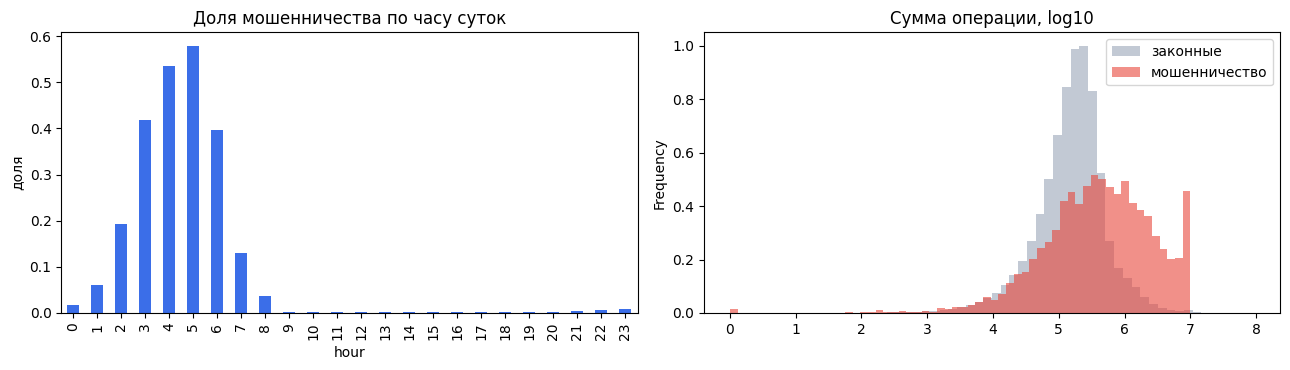

,ops,fraud,fraud_rate
step,,,
"(0, 200]",1045328,2254,0.0022
"(200, 400]",1484208,2223,0.0015
"(400, 600]",197323,2136,0.0108
"(600, 744]",43550,1600,0.0367


In [5]:
df = raw[raw.type.isin(["TRANSFER", "CASH_OUT"])].copy()
df = df.sort_values("step", kind="mergesort").reset_index(drop=True)   # порядок внутри часа сохраняем как в файле
df["seq"] = np.arange(len(df))
df["hour"] = df.step % 24
print(f"TRANSFER + CASH_OUT: {len(df):,} операций, мошенничество {df.isFraud.mean():.3%}")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
df.groupby("hour").isFraud.mean().plot.bar(ax=ax[0], color="#3b6ee8")
ax[0].set_title("Доля мошенничества по часу суток"); ax[0].set_ylabel("доля")
for f, c in [(0, "#9aa5b8"), (1, "#e8463b")]:
    np.log10(df.loc[df.isFraud == f, "amount"] + 1).plot.hist(ax=ax[1], bins=60, alpha=.6, density=True,
                                                              color=c, label="мошенничество" if f else "законные")
ax[1].set_title("Сумма операции, log10"); ax[1].legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/paysim_eda.png", dpi=120); plt.show()

steps = df.groupby(pd.cut(df.step, [0, 200, 400, 600, 744])).agg(ops=("isFraud", "size"), fraud=("isFraud", "sum"))
steps["fraud_rate"] = steps.fraud / steps.ops
steps   # в PaySim законных операций мало в поздних шагах — доля мошенничества в тесте будет выше

### Действующее правило PaySim (AS-IS)
`isFlaggedFraud` — встроенное правило симулятора (перевод более 200 тыс.). Это точка отсчёта «как сейчас».

In [6]:
asis = metrics(df.isFraud, df.isFlaggedFraud, 1, df.amount)
pd.Series(asis)[["TP", "FP", "FN", "precision", "recall", "FPR", "amount_recall"]]

TP                 16.0000
FP                  0.0000
FN              8,197.0000
precision           1.0000
recall              0.0019
FPR                 0.0000
amount_recall       0.0065
dtype: float64

## 2. Проверка утечки через балансы
В PaySim балансы записаны **после** операции, а у мошеннических переводов симулятор не обновляет баланс получателя.
Модель на этих колонках «угадывает» мошенничество по артефакту, которого у банка в момент решения нет
(баланс счёта получателя в другом банке банку не виден). Покажем это и исключим колонки.

In [7]:
BAL = ["oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest"]
chk = pd.DataFrame({
    "получатель: баланс 0 до и после":   (df.oldbalanceDest.eq(0) & df.newbalanceDest.eq(0)),
    "ошибка баланса получателя ≠ 0":     (df.oldbalanceDest + df.amount - df.newbalanceDest).abs() > 1,
    "сумма = весь баланс отправителя":   (df.amount - df.oldbalanceOrg).abs() < 1,
    "баланс отправителя после = 0":      df.newbalanceOrig.eq(0),
}).groupby(df.isFraud).mean().T
chk.columns = ["законные", "мошенничество"]
chk

,законные,мошенничество
получатель: баланс 0 до и после,0.0006,0.4963
ошибка баланса получателя ≠ 0,0.0961,0.5158
сумма = весь баланс отправителя,0.0000,0.9782
баланс отправителя после = 0,0.9010,0.9805


## 3. Признаки без балансов
Только то, что банк знает в момент операции. История — строго по прошлым операциям (`past_stats`).

In [8]:
df["is_transfer"] = (df.type == "TRANSFER").astype(int)
df["log_amount"] = np.log1p(df.amount)
df["is_night"] = df.hour.between(0, 5).astype(int)

# Получатель: насколько он «новый» и типична ли для него сумма
d = past_stats(df, ["nameDest"], "seq", "amount")
df["dest_prev_cnt"] = d.cnt
df["dest_new"] = (d.cnt == 0).astype(int)
df["amt_to_dest_mean"] = df.amount / d["mean"]
df["dest_cnt_24h"] = past_stats(df, ["nameDest"], "step", "amount", window=24).cnt

# Отправитель: сумма относительно его истории
o = past_stats(df, ["nameOrig"], "seq", "amount")
df["orig_prev_cnt"] = o.cnt
df["amt_to_orig_mean"] = df.amount / o["mean"]
print(f"У отправителя есть история в {(o.cnt > 0).mean():.2%} операций — в PaySim почти все отправители разовые")

# Связка «перевод → вывод»: перед операцией в этом или прошлом часе была операция на ту же сумму
g = df.groupby("amount", sort=False)
prev_step, prev_type = g.step.shift(1), g.type.shift(1)
df["same_amt_recent"] = ((df.step - prev_step) <= 1).astype(int)
df["after_transfer_same_amt"] = (df.same_amt_recent.eq(1) & prev_type.eq("TRANSFER")).astype(int)

FEATURES = ["is_transfer", "log_amount", "hour", "is_night",
            "dest_prev_cnt", "dest_new", "amt_to_dest_mean", "dest_cnt_24h",
            "orig_prev_cnt", "amt_to_orig_mean", "same_amt_recent", "after_transfer_same_amt",
            "amt_to_type_median"]
df[FEATURES[:-1]].describe().T[["mean", "min", "max"]]

У отправителя есть история в 0.06% операций — в PaySim почти все отправители разовые


,mean,min,max
is_transfer,0.1924,0.0000,1.0000
log_amount,11.9278,0.0000,18.3421
hour,15.3088,0.0000,23.0000
is_night,0.0101,0.0000,1.0000
dest_prev_cnt,5.2912,0.0000,74.0000
dest_new,0.1839,0.0000,1.0000
amt_to_dest_mean,inf,0.0000,inf
dest_cnt_24h,1.1161,0.0000,57.0000
orig_prev_cnt,0.0006,0.0000,2.0000
amt_to_orig_mean,7.9130,0.0001,"4,983.1204"


## 4. Сплит по времени и обучение

In [9]:
tr, va, te = time_split(df, "step")
tr, va, te = tr.copy(), va.copy(), te.copy()
# сумма относительно медианы своего типа — медиану берём только из train
med = tr.groupby("type").amount.median()
for part in (tr, va, te):
    part["amt_to_type_median"] = part.amount / part.type.map(med).astype(float)
for n_, p_ in [("train", tr), ("valid", va), ("test", te)]:
    print(f"{n_:5s}: шаги {p_.step.min()}–{p_.step.max()}, {len(p_):,} операций, мошенничество {p_.isFraud.mean():.3%}")

PARAMS = dict(objective="binary", metric="average_precision", learning_rate=0.05, num_leaves=63,
              min_child_samples=100, feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1,
              verbose=-1, seed=42)

def fit(cols):
    m = lgb.train(PARAMS, lgb.Dataset(tr[cols], tr.isFraud), 2000,
                  valid_sets=[lgb.Dataset(va[cols], va.isFraud)],
                  callbacks=[lgb.early_stopping(100, verbose=False)])
    return m, m.predict(va[cols]), m.predict(te[cols])

model, va["score"], te["score"] = fit(FEATURES)
print("итераций:", model.best_iteration)

train: шаги 1–281, 1,672,907 операций, мошенничество 0.191%
valid: шаги 282–354, 544,998 операций, мошенничество 0.140%
test : шаги 355–743, 552,504 операций, мошенничество 0.771%
итераций: 3


Для сравнения — модель **с балансами**. Если её качество близко к 100%, это подтверждает утечку:
такие цифры нельзя выносить на слайды.

In [10]:
LEAK = FEATURES + BAL
_, va_leak, te_leak = fit(LEAK)

## 5. Метрики
Рабочая точка бейзлайна: порог, при котором на **валидации** ложные срабатывания среди законных (FPR) не выше 1%.
Пороги по цене ошибки подбираются в ноутбуке 03.

In [11]:
TARGET_FPR = 0.01
thr = threshold_for_fpr(va.isFraud, va.score, TARGET_FPR)
thr_leak = threshold_for_fpr(va.isFraud, va_leak, TARGET_FPR)

rows = []
for variant, s_va, s_te, t, data in [
        ("AS-IS: правило isFlaggedFraud", va.isFlaggedFraud, te.isFlaggedFraud, 1, None),
        ("С балансами (утечка, не использовать)", va_leak, te_leak, thr_leak, None),
        ("Бейзлайн", va.score, te.score, thr, None)]:
    for split, part, s in [("valid", va, s_va), ("test", te, s_te)]:
        m = metrics(part.isFraud, s, t, part.amount)
        m.update(dataset="PaySim", variant=variant, split=split)
        rows.append(m)
res = pd.DataFrame(rows)
COLS = ["dataset", "variant", "split", "n", "n_fraud", "TP", "FP", "FN",
        "precision", "recall", "FPR", "false_signal_share", "amount_recall", "roc_auc", "pr_auc", "threshold"]
res[COLS]

,dataset,variant,split,n,n_fraud,TP,FP,FN,precision,recall,FPR,false_signal_share,amount_recall,roc_auc,pr_auc,threshold
0,PaySim,AS-IS: правило isFlaggedFraud,valid,544998,762,0,0,762,NaN,0.0000,0.0000,NaN,0.0000,0.5000,0.0014,1.0000
1,PaySim,AS-IS: правило isFlaggedFraud,test,552504,4258,13,0,4245,1.0000,0.0031,0.0000,0.0000,0.0106,0.5015,0.0107,1.0000
2,PaySim,"С балансами (утечка, не использовать)",valid,544998,762,754,5442,8,0.1217,0.9895,0.0100,0.8783,0.9963,0.9890,0.6450,0.0001
3,PaySim,"С балансами (утечка, не использовать)",test,552504,4258,4212,4335,46,0.4928,0.9892,0.0079,0.5072,0.9967,0.9899,0.9858,0.0001
4,PaySim,Бейзлайн,valid,544998,762,549,5423,213,0.0919,0.7205,0.0100,0.9081,0.8099,0.9391,0.2316,0.0075
5,PaySim,Бейзлайн,test,552504,4258,3109,2753,1149,0.5304,0.7302,0.0050,0.4696,0.8223,0.9456,0.7368,0.0075


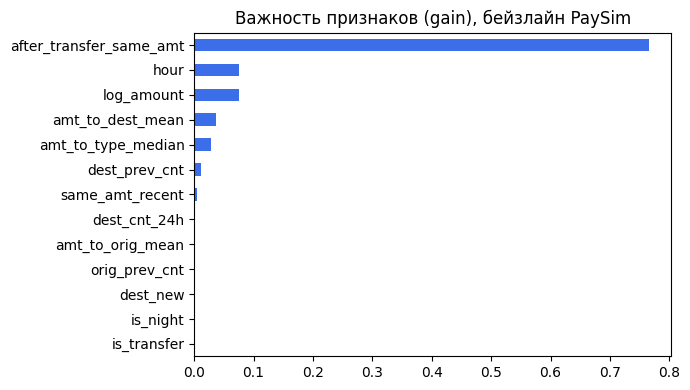

In [12]:
imp = pd.Series(model.feature_importance("gain"), index=FEATURES).sort_values()
(imp / imp.sum()).plot.barh(figsize=(7, 4), color="#3b6ee8", title="Важность признаков (gain), бейзлайн PaySim")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/paysim_importance.png", dpi=120); plt.show()

## 6. Сохранение
Строки для листа «Метрики моделей» и скоры для ноутбука 03.

In [13]:
res[COLS].to_csv(f"{OUT_DIR}/metrics_paysim.csv", index=False)
scores = pd.concat([va.assign(split="valid"), te.assign(split="test")])
scores[["split", "step", "type", "amount", "isFraud", "score"]].to_csv(f"{OUT_DIR}/paysim_scores.csv.gz", index=False)
print("Сохранено в", OUT_DIR, ":", sorted(os.listdir(OUT_DIR)))

Сохранено в /kaggle/working : ['__notebook__.ipynb', '__pycache__', 'antifraud_utils.py', 'metrics_paysim.csv', 'paysim_eda.png', 'paysim_importance.png', 'paysim_scores.csv.gz']


## Выводы для слайда
- **Утечка подтверждена.** Модель с колонками балансов даёт на тесте PR-AUC 0,986 и полноту 98,9% — это артефакт симулятора (баланс получателя в другом банке банку не виден). В решении балансы не используются.
- **Бейзлайн без балансов** (порог FPR ≤ 1% на валидации), тест: полнота **73,0%**, ложных среди законных **0,50%**, точность 53,0%, остановлено **82,2%** похищаемой суммы. ROC-AUC 0,946.
- **Действующее правило PaySim** (`isFlaggedFraud`, перевод > 200 тыс.): поймано 13 из 4 258 хищений (0,3%), остановлено 1,1% суммы.
- Главный признак — связка «перевод → вывод той же суммы» (`after_transfer_same_amt`, ~77% важности): это ровно сценарий вывода через дропов.
- Оговорка: доля мошенничества в валидации 0,14%, в тесте 0,77% (особенность PaySim), поэтому точность и PR-AUC между ними несравнимы; сравниваем полноту, FPR и долю остановленной суммы. Ранняя остановка сработала на 3 деревьях — бейзлайн специально простой, основная модель в ноутбуке 02.